In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
import xgboost as xgb

import sys
!{sys.executable} -m pip install xgboost

In [2]:
file_path = "/Users/danisanchez/Downloads/Waves_2023.txt" #buoy data 
df_buoy = pd.read_csv(file_path, sep=r'\s+')

fileName = "/Users/danisanchez/Downloads/LA_AQS_2023.csv" #epa aqs data
pd.read_csv(fileName)
df_epa = pd.read_csv(fileName)

In [3]:
print("EPA columns:", df_epa.columns.tolist())
print(df_epa.head(2))

print("\nBuoy columns:", df_buoy.columns.tolist())
print(df_buoy.head(2))

EPA columns: ['State Code', 'County Code', 'Site Number', 'Parameter Code', 'POC', 'Latitude', 'Longitude', 'Datum', 'Parameter Name', 'Duration Description', 'Pollutant Standard', 'Date (Local)', 'Year', 'Day In Year (Local)', 'Units of Measure', 'Exceptional Data Type', 'Nonreg Observation Count', 'Observation Count', 'Observation Percent', 'Nonreg Arithmetic Mean', 'Arithmetic Mean', 'Nonreg First Maximum Value', 'First Maximum Value', 'First Maximum Hour', 'AQI', 'Daily Criteria Indicator', 'Tribe Name', 'State Name', 'County Name', 'City Name', 'Local Site Name', 'Address', 'MSA or CBSA Name', 'Data Source']
   State Code  County Code  Site Number  Parameter Code  POC  Latitude  \
0           6           37         1103           68103    1  34.06659   
1           6           37         1103           42602    3  34.06659   

   Longitude  Datum           Parameter Name Duration Description  ... AQI  \
0 -118.22688  WGS84  Ambient Min Temperature              24 HOUR  ...   .   


In [4]:
#BUOY DATA

In [5]:
df_buoy = df_buoy.replace([99.0, 999.0, 9999.0], np.nan)
df_buoy = df_buoy.dropna(subset=["WVHT", "DPD", "APD", "MWD", "WTMP"])

buoy_features = ["DPD", "APD", "MWD", "WTMP"]
X_buoy = df_buoy[buoy_features]
y_buoy = df_buoy["WVHT"]

In [6]:
X_train_b, X_temp_b, y_train_b, y_temp_b = train_test_split(
    X_buoy, y_buoy, test_size=0.4, random_state=42
)
X_val_b, X_test_b, y_val_b, y_test_b = train_test_split(
    X_temp_b, y_temp_b, test_size=0.5, random_state=42
)

In [7]:
#EPA DATA

In [8]:
all_pollutants = df_epa["Parameter Name"].unique()
no2_name = [
    p for p in all_pollutants if "NO2" in p or "Nitrogen dioxide" in p
][0]
o3_name = [p for p in all_pollutants if "Ozone" in p or "O3" in p][0]
pm25_name = [p for p in all_pollutants if "PM2.5" in p or "PM25" in p][0]

In [9]:
df_filtered = df_epa[
    df_epa["Parameter Name"].isin([no2_name, o3_name, pm25_name])
]
df_pivoted = df_filtered.pivot_table(
    index=["Date (Local)", "Site Number"],
    columns="Parameter Name",
    values="Arithmetic Mean",
).dropna()

df_pivoted = df_pivoted.rename(
    columns={no2_name: "NO2", o3_name: "O3", pm25_name: "PM25"}
).reset_index()

In [10]:
df_pivoted["Date (Local)"] = pd.to_datetime(df_pivoted["Date (Local)"])
df_pivoted["Month"] = df_pivoted["Date (Local)"].dt.month


def get_season(month):
    if month in (6, 7, 8):
        return "summer"
    elif month in (12, 1, 2):
        return "winter"
    return None


df_pivoted["Season"] = df_pivoted["Month"].apply(get_season)
df_ml = df_pivoted.dropna(subset=["Season"]).copy()
df_ml["Target"] = df_ml["Season"].map({"summer": 1, "winter": 0})

In [19]:
epa_features = ["O3", "NO2", "PM25"]
X_epa = df_ml[epa_features]
y_epa = df_ml["Target"]

X_train_val, X_epa_test, y_train_val, y_epa_test = train_test_split(
    X_epa, y_epa, test_size=0.2, random_state=42
)
X_epa_train, X_epa_val, y_epa_train, y_epa_val = train_test_split(
    X_train_val, y_train_val, test_size=0.25, random_state=42
)

# 5. Scale features & fit your optimal RidgeClassifier(alpha=100.0)
scaler_epa = StandardScaler()
X_epa_train_scaled = scaler_epa.fit_transform(X_epa_train)
X_epa_test_scaled = scaler_epa.transform(X_epa_test)

final_ridge = RidgeClassifier(alpha=100.0)
final_ridge.fit(X_epa_train_scaled, y_epa_train)

print(
    "Verified Test Error:",
    round(1 - final_ridge.score(X_epa_test_scaled, y_epa_test), 4),
)

# 6. Compute Permutation Feature Importance & Plot Barchart
perm_epa = permutation_importance(
    final_ridge,
    X_epa_test_scaled,
    y_epa_test,
    n_repeats=30,
    random_state=42,
    n_jobs=-1,
)
sorted_idx = perm_epa.importances_mean.argsort()

Verified Test Error: 0.0323


In [20]:
#models/plot

In [21]:
epa_linear = RidgeClassifier(alpha=100.0, random_state=42)
epa_linear.fit(X_epa_train_scaled, y_epa_train)

xgb_optimal = xgb.XGBRegressor(
    n_estimators=40, objective="reg:squarederror", random_state=42
)
xgb_optimal.fit(X_train_b, y_train_b)

dt_optimal = DecisionTreeRegressor(max_depth=6, random_state=42)
dt_optimal.fit(X_train_b, y_train_b)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.For an example of how ``max_depth`` influences the model, see:ref:`sphx_glr_auto_examples_tree_plot_tree_regression.py`.",6
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 0.24 Poisson deviance criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``

In [22]:
lr_optimal = LinearRegression()
lr_optimal.fit(X_train_b, y_train_b)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](4,)","[-0.02, 0.12, 0. ,-0.04]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](4,)","['DPD','APD','MWD','WTMP']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,0.6467
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,4
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(4)


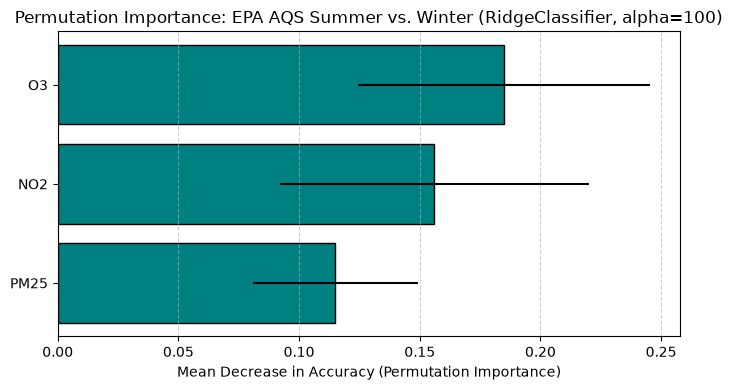

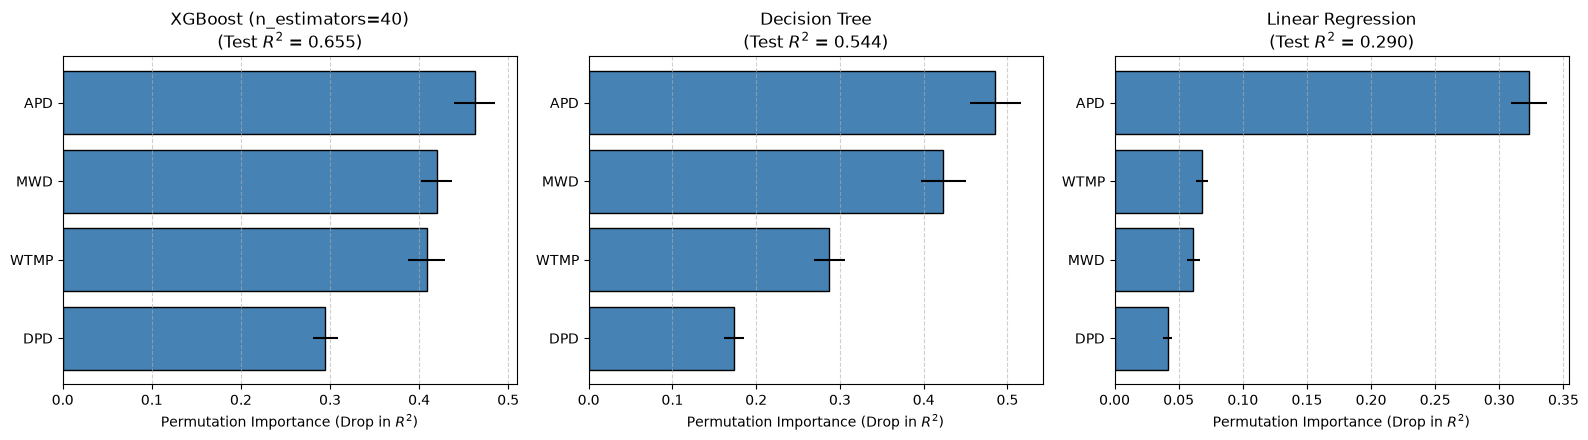

In [23]:
#epa data
plt.figure(figsize=(7, 4))
plt.barh(
    np.array(epa_features)[sorted_idx],
    perm_epa.importances_mean[sorted_idx],
    xerr=perm_epa.importances_std[sorted_idx],
    color="teal",
    edgecolor="black",
)
plt.xlabel("Mean Decrease in Accuracy (Permutation Importance)")
plt.title(
    "Permutation Importance: EPA AQS Summer vs. Winter (RidgeClassifier,"
    " alpha=100)"
)
plt.grid(axis="x", linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

#buoy

buoy_models = {
    "XGBoost (n_estimators=40)": xgb_optimal,
    "Decision Tree": dt_optimal,
    "Linear Regression": lr_optimal,
}

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

for ax, (name, model) in zip(axes, buoy_models.items()):
    perm = permutation_importance(
        model, X_test_b, y_test_b, n_repeats=30, random_state=42, n_jobs=-1
    )
    sorted_idx = perm.importances_mean.argsort()

    ax.barh(
        np.array(buoy_features)[sorted_idx],
        perm.importances_mean[sorted_idx],
        xerr=perm.importances_std[sorted_idx],
        color="steelblue",
        edgecolor="black",
    )
    ax.set_title(f"{name}\n(Test $R^2$ = {model.score(X_test_b, y_test_b):.3f})")
    ax.set_xlabel("Permutation Importance (Drop in $R^2$)")
    ax.grid(axis="x", linestyle="--", alpha=0.6)

plt.tight_layout()
plt.show()

In [24]:
print("Test error:", 1 - epa_linear.score(X_epa_test_scaled, y_epa_test))

Test error: 0.032258064516129004
